In [4]:
SELECT * FROM 'cs-content-cache-trace-filter.csv';

,Timestamp,ContentID,Event
0,0.000,/data1/seq=14,hit
1,0.000,/data1/seq=76,hit
2,0.000,/data1/seq=18,hit
3,0.000,/data1/seq=2,hit
4,0.000,/localhost/nfd/faces/events/seq=4,hit
...,...,...,...
1048570,333.209,/%D0%3F%E0D%1A/seq=0,evict
1048571,333.209,/%D0%3F%E0D%1A/seq=0,evict
1048572,333.210,/%D0%3F%E0D%1A/seq=0,evict
1048573,333.210,/data1/seq=94,hit


In [5]:
import pandas as pd
import numpy as np

# Load the uploaded dataset to examine its structure
#file_path = '/mnt/data/cs-content-cache-trace-filter.csv'
#data = pd.read_csv(file_path)

# Only keep 'hit' events since they represent requests
data = df[df['Event'] == 'hit']

# Display basic information about the dataset
data.info(), data.head()


<class 'pandas.core.frame.DataFrame'>
Index: 362207 entries, 0 to 1048574
Data columns (total 3 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   Timestamp  362207 non-null  float64
 1   ContentID  362207 non-null  object 
 2   Event      362207 non-null  object 
dtypes: float64(1), object(2)
memory usage: 11.1+ MB


(None,
    Timestamp                          ContentID Event
 0        0.0                      /data1/seq=14   hit
 1        0.0                      /data1/seq=76   hit
 2        0.0                      /data1/seq=18   hit
 3        0.0                       /data1/seq=2   hit
 4        0.0  /localhost/nfd/faces/events/seq=4   hit)

In [6]:
# Convert Timestamp to milliseconds for clarity in calculations
data['Timestamp'] = data['Timestamp'] * 1000

# Calculate frequency: Number of events per ContentID
frequency = data.groupby('ContentID').size().reset_index(name='frequency')

# Calculate recency: Time since the last event per ContentID
last_timestamp = data.groupby('ContentID')['Timestamp'].max().reset_index(name='last_event_time')
current_time = data['Timestamp'].max()
last_timestamp['recency'] = current_time - last_timestamp['last_event_time']

# Merge the computed features
aggregated_data = frequency.merge(last_timestamp, on='ContentID')

# Display the aggregated data for exploration
aggregated_data.head()


,ContentID,frequency,last_event_time,recency
0,/data1/seq=1,718,328907.0,4303.0
1,/data1/seq=10,1895,333179.0,31.0
2,/data1/seq=100,1513,332686.0,524.0
3,/data1/seq=11,1834,333000.0,210.0
4,/data1/seq=12,1874,333047.0,163.0


In [7]:
# Define weights for calculating popularity score
alpha = 0.7  # Weight for frequency
beta = 0.3   # Weight for recency (inverse relationship)

# Calculate popularity score
aggregated_data['popularity_score'] = (
    alpha * aggregated_data['frequency'] +
    beta * (1 / (aggregated_data['recency'] + 1))  # Adding 1 to avoid division by zero
)

# Normalize the popularity score for consistency
aggregated_data['popularity_score'] = (
    aggregated_data['popularity_score'] / aggregated_data['popularity_score'].max()
) * 10000

aggregated_data['popularity_score'] = np.round(aggregated_data['popularity_score'], decimals=3)

# Display the updated dataset with the popularity score
aggregated_data.head()


,ContentID,frequency,last_event_time,recency,popularity_score
0,/data1/seq=1,718,328907.0,4303.0,3191.108
1,/data1/seq=10,1895,333179.0,31.0,8422.272
2,/data1/seq=100,1513,332686.0,524.0,6724.440
3,/data1/seq=11,1834,333000.0,210.0,8151.111
4,/data1/seq=12,1874,333047.0,163.0,8328.891


In [8]:
import pandas as pd

# Load the dataset
data = aggregated_data

# Display the column names
print("Available columns in the dataset:")
print(data.columns)

Available columns in the dataset:
Index(['ContentID', 'frequency', 'last_event_time', 'recency',
       'popularity_score'],
      dtype='object')


Mean Squared Error: 61099.3357
R-Squared: 0.9808
Model saved as popularity_predictor.pkl


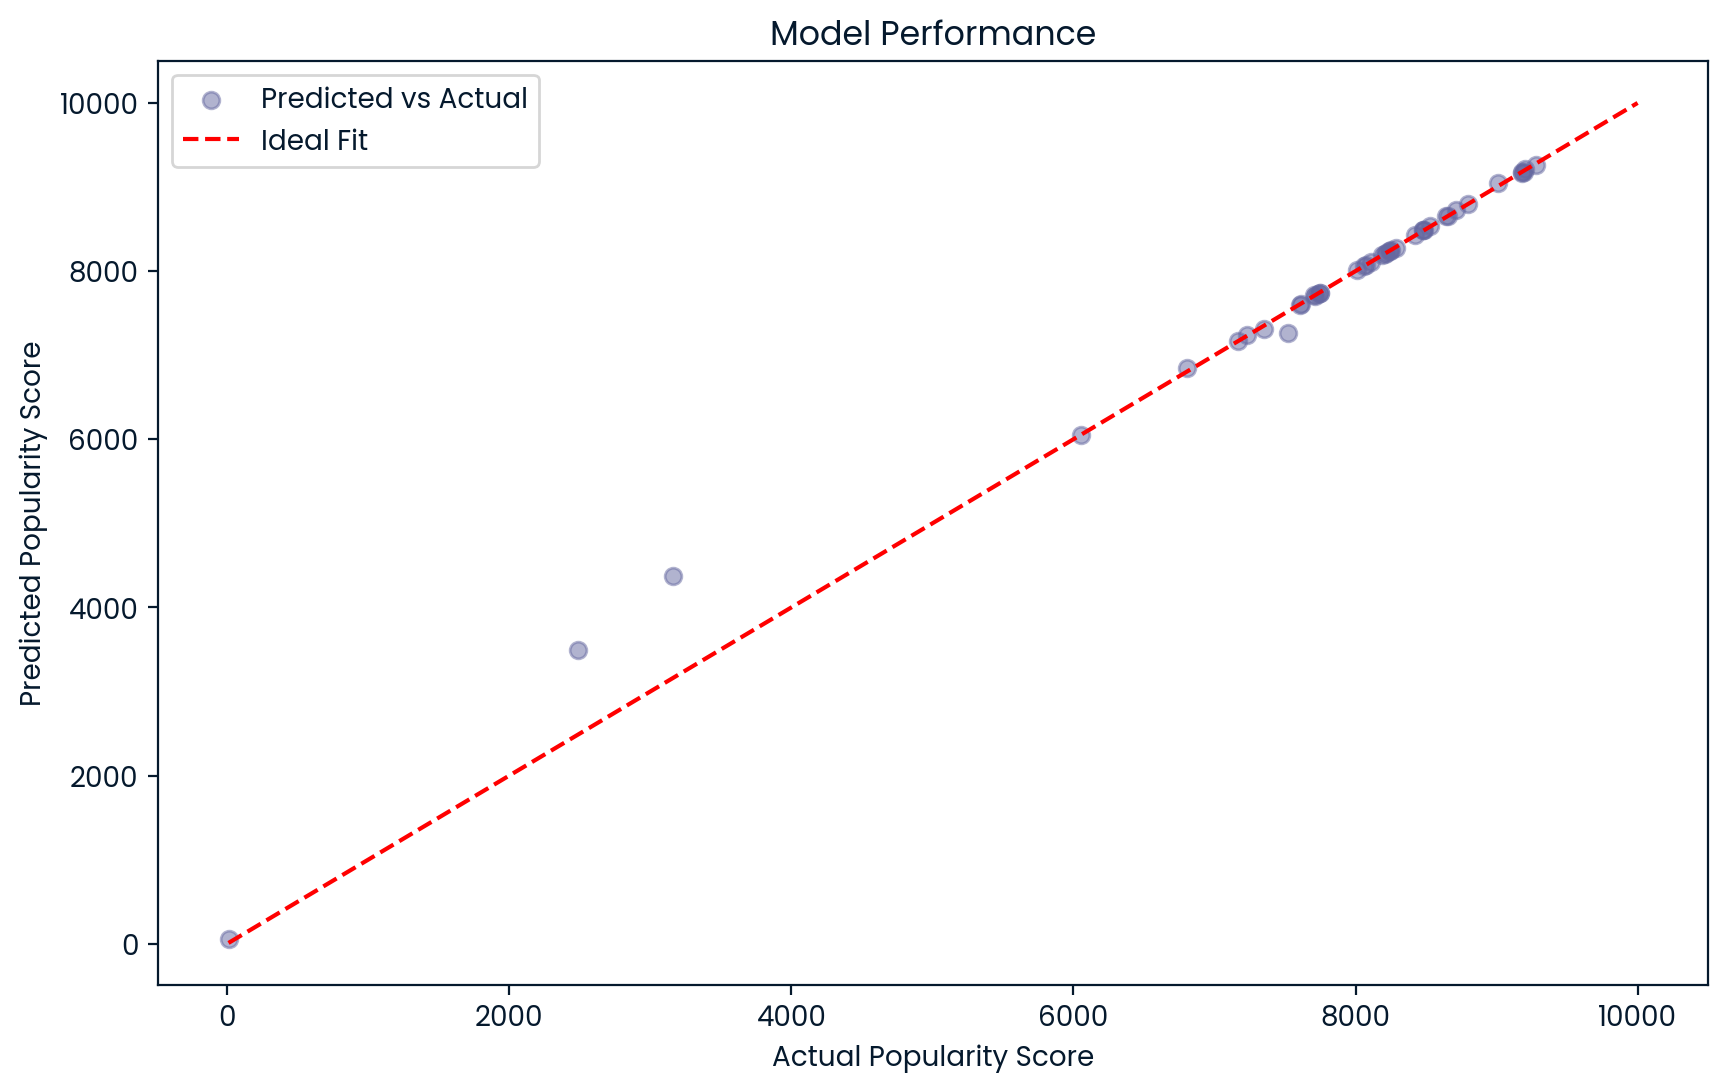

Predictions saved as predicted_popularity_scores.csv


In [9]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score
import matplotlib.pyplot as plt
import joblib

# Prepare the data
features = ['frequency', 'last_event_time', 'recency']
target = 'popularity_score'

# Extract ContentID for reference
content_ids = data['ContentID']

X = data[features]
y = data[target]

# Split the data into train and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Train a Random Forest Regressor
model = RandomForestRegressor(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

# Predict on the test set
y_pred = model.predict(X_test)

# Evaluate the model
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Mean Squared Error: {mse:.4f}")
print(f"R-Squared: {r2:.4f}")

# Save the model
joblib.dump(model, "popularity_predictor.pkl")
print("Model saved as popularity_predictor.pkl")

# Visualize predictions vs actual
plt.figure(figsize=(10, 6))
plt.scatter(y_test, y_pred, alpha=0.5, label='Predicted vs Actual')
plt.plot([y.min(), y.max()], [y.min(), y.max()], '--r', label='Ideal Fit')
plt.xlabel('Actual Popularity Score')
plt.ylabel('Predicted Popularity Score')
plt.title('Model Performance')
plt.legend()
plt.show()

# Prepare the output with predictions
X_test['ContentID'] = content_ids.iloc[X_test.index].values  # Add ContentID to the test set
X_test['predicted_popularity_score'] = y_pred               # Add predicted scores
X_test['predicted_popularity_score'] = np.round(X_test['predicted_popularity_score'], decimals=3)  # Round predictions

# Save the predictions to CSV
X_test[['ContentID', 'predicted_popularity_score']].to_csv("predicted_popularity_scores.csv", index=False)
print("Predictions saved as predicted_popularity_scores.csv")
